In [ ]:
# =============================================================================
# Análise e Exploração dos dados
# =============================================================================

In [ ]:
# =============================================================================
# Bibliotecas python
# =============================================================================
import pandas as pd
import os

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# =============================================================================
# Configuração
# =============================================================================

# 1. Configuração caminho dos arquivos
#exitem diversas formas de fazer optei por uma forma simples e direta.
raiz_pasta = '.' 
pasta_arquivos = os.path.join(raiz_pasta, 'arquivos')

# 2. Mapeando nome dos arquivos.
# podemos deixar essa forma mais dinamica se ncessário.
# arquivo com o consumo de dados
caminho_consumo = os.path.join(pasta_arquivos, 'consumo_dados.csv')
# arquivo com a relação de usuários e áreas
caminho_usuarios = os.path.join(pasta_arquivos, 'usuarios_areas.csv')
# arquivo com a relação de áreas e lideranças
caminho_areas = os.path.join(pasta_arquivos, 'areas_lideranca.csv')
# arquivo com relação de preços dos produtos
caminho_precos = os.path.join(pasta_arquivos, 'catalogo_precos.csv')

# 3. Importando para os DataFrames (df)
try:
    df_consumo = pd.read_csv(caminho_consumo)
    df_usuarios = pd.read_csv(caminho_usuarios)
    df_areas = pd.read_csv(caminho_areas)
    df_precos = pd.read_csv(caminho_precos)
    
    print("Todos os arquivos foram importados com sucesso da pasta 'arquivos'!")
    # Exibindo uma amostra rápida para confirmar
    print(f"\nTotal de registros importados: Consumo ({len(df_consumo)}), Usuários ({len(df_usuarios)})")
    
    # Caso ocorrer algum erro na importação dos arquivos
except FileNotFoundError as e:
    print(f"Erro ao encontrar o arquivo. Verifique se a pasta e os arquivos existem: {e}")


Todos os arquivos foram importados com sucesso da pasta 'arquivos'!

Total de registros importados: Consumo (6), Usuários (5)


In [6]:
 # Exemplo arquivo consumo_dados.csv
df_consumo

,id_log,data_consumo,id_usuario,produto_dado,qtd_consultas
0,1,2026-10-01,USR001,TB_SERASA_SCORE,1500
1,2,2026-10-01,USR002,TB_BACEN_SCR,300
2,3,2026-10-02,USR003,TB_SERASA_SCORE,2500
3,4,2026-10-02,USR001,TB_BUREAU_FRAUDE,800
4,5,2026-10-03,USR004,TB_BACEN_SCR,120
5,6,2026-10-03,USR005,TB_RECEITA_FEDERAL,50


In [ ]:
# =============================================================================
# Tratamento e Transformação dos Dados
# =============================================================================

# 4. Transformação 

# Fase 1: Enriquecendo o Consumo com dados de Usuários e Áreas
df_step1 = df_consumo.merge(df_usuarios, on='id_usuario', how='left')
df_step2 = df_step1.merge(df_areas, on='id_area', how='left')

# Fase 2: Tratamento de Governança: Quem é da AREA_99 (Juliana Costa) vai ficar sem área, então tratamos os vazios
df_step2['nome_area'] = df_step2['nome_area'].fillna('Área Não Mapeada (Órfão)')
df_step2['possui_lider_negocio'] = df_step2['possui_lider_negocio'].fillna('Nao_Mapeado')
df_step2['respo_area'] = df_step2['respo_area'].fillna('Nao_Mapeado')
df_step2['nome_lider'] = df_step2['nome_lider'].fillna('Sem Lideranca')

# Fase 3: Cruzando com o valor financeiro
df_final = df_step2.merge(df_precos, on='produto_dado', how='left')

# Fase 4: Calculando o Custo (Qtd Consultas * Valor Unitário)
df_final['custo_total'] = df_final['qtd_consultas'] * df_final['valor_unitario']

print("Visão da Base Detalhada (Log a Log):")
display(df_final)

Visão da Base Detalhada (Log a Log):


,id_log,data_consumo,id_usuario,produto_dado,qtd_consultas,nome_usuario,id_area,nome_area,respo_area,possui_lider_negocio,nome_lider,fornecedor,valor_unitario,custo_total
0,1,2026-10-01,USR001,TB_SERASA_SCORE,1500,Carlos Silva,AREA_01,Risco e Credito,Joao Barros,Sim,Mariana Barros,Serasa Experian,0.45,675.0
1,2,2026-10-01,USR002,TB_BACEN_SCR,300,Ana Souza,AREA_02,Prevencao a Fraudes,Anita Oliveira,Sim,Pedro Alves,Banco Central,0.15,45.0
2,3,2026-10-02,USR003,TB_SERASA_SCORE,2500,Fernanda Lima,AREA_01,Risco e Credito,Joao Barros,Sim,Mariana Barros,Serasa Experian,0.45,1125.0
3,4,2026-10-02,USR001,TB_BUREAU_FRAUDE,800,Carlos Silva,AREA_01,Risco e Credito,Joao Barros,Sim,Mariana Barros,ClearSale,0.80,640.0
4,5,2026-10-03,USR004,TB_BACEN_SCR,120,Roberto Dias,AREA_03,Marketing Digital,Jose Luis,Nao,Sem Lideranca Direta,Banco Central,0.15,18.0
5,6,2026-10-03,USR005,TB_RECEITA_FEDERAL,50,Juliana Costa,AREA_99,Área Não Mapeada (Órfão),Nao_Mapeado,Nao_Mapeado,Sem Lideranca,Serpro,0.25,12.5


In [ ]:
# =============================================================================
# VISÕES ANALÍTICAS (FINOPS)
# =============================================================================
###Exemplo de visões que pode ser geradas a partir da base final, tratada.
##são as mesmas que podemos exportar para outra ferramenta de BI, como Power BI, Tableau, Qlik, etc.

# 1. Custo gerado por Fornecedor, rateado por Área
visao_fornecedor_area = df_final.groupby(
    ['fornecedor', 'nome_area']
)['custo_total'].sum().reset_index()

# Ordenando pelo fornecedor e, dentro dele, pela área que mais gastou
visao_fornecedor_area = visao_fornecedor_area.sort_values(by=['fornecedor', 'custo_total'], ascending=[True, False])
visao_fornecedor_area['custo_total_formatado'] = visao_fornecedor_area['custo_total'].apply(lambda x: f"R$ {x:,.2f}")

print("1. CUSTO DE FORNECEDOR RATEADO POR ÁREA:")
display(visao_fornecedor_area[['fornecedor', 'nome_area', 'custo_total_formatado']])
print("\n" + "="*60 + "\n")


# 2. Visão Macro por Fornecedor
# Quem é o fornecedor que leva a maior fatia do seu orçamento?
visao_fornecedor_macro = df_final.groupby('fornecedor')['custo_total'].sum().reset_index()
visao_fornecedor_macro = visao_fornecedor_macro.sort_values(by='custo_total', ascending=False)
visao_fornecedor_macro['custo_total_formatado'] = visao_fornecedor_macro['custo_total'].apply(lambda x: f"R$ {x:,.2f}")

print("2. CUSTO TOTAL POR FORNECEDOR (Share of Wallet):")
display(visao_fornecedor_macro[['fornecedor', 'custo_total_formatado']])
print("\n" + "="*60 + "\n")


# 3. Produtos/Bases Mais Caras (Eficiência de Contrato)
# Qual API ou tabela de dados está gerando mais despesa?
visao_produto = df_final.groupby(['produto_dado', 'fornecedor'])['custo_total'].sum().reset_index()
visao_produto = visao_produto.sort_values(by='custo_total', ascending=False)
visao_produto['custo_total_formatado'] = visao_produto['custo_total'].apply(lambda x: f"R$ {x:,.2f}")

print("3. RANKING DE PRODUTOS DE DADOS MAIS CAROS:")
display(visao_produto[['produto_dado', 'fornecedor', 'custo_total_formatado']])
print("\n" + "="*60 + "\n")


# 4. Top 5 Usuários (Detecção de Anomalias/Heavy Users)
# Visão essencial para encontrar robôs em loop ou usuários consumindo fora do padrão
visao_usuarios = df_final.groupby(['nome_usuario', 'nome_area', 'fornecedor'])['custo_total'].sum().reset_index()
visao_usuarios = visao_usuarios.sort_values(by='custo_total', ascending=False).head(5)
visao_usuarios['custo_total_formatado'] = visao_usuarios['custo_total'].apply(lambda x: f"R$ {x:,.2f}")

print("4. TOP 5 USUÁRIOS COM MAIOR CUSTO (Heavy Users):")
display(visao_usuarios[['nome_usuario', 'nome_area', 'fornecedor', 'custo_total_formatado']])

# 5. RATEIO POR ÁREA COM LÍDER OU RESPONSÁVEL
# 5.1 Criando uma coluna condicional para definir quem será exibido como responsável
# Se a coluna 'possui_lider_negocio' for 'Sim', usamos o 'nome_lider'. Caso contrário, usamos o 'respo_area'.
df_final['responsavel_exibicao'] = df_final.apply(
    lambda row: row['nome_lider'] if row['possui_lider_negocio'] == 'Sim' else row['respo_area'], 
    axis=1
)

# 5.2 Agrupando a nova visão solicitada
visao_responsavel = df_final.groupby(
    ['nome_area', 'possui_lider_negocio', 'responsavel_exibicao']
)['custo_total'].sum().reset_index()

# 5.3 Ordenando pelo maior custo e criando a coluna formatada
visao_responsavel = visao_responsavel.sort_values(by='custo_total', ascending=False)
visao_responsavel['custo_total_formatado'] = visao_responsavel['custo_total'].apply(lambda x: f"R$ {x:,.2f}")

# 5.4 Exibindo o resultado final
print("NOVA VISÃO: RATEIO POR ÁREA COM LÍDER OU RESPONSÁVEL")
display(visao_responsavel[['nome_area', 'possui_lider_negocio', 'responsavel_exibicao', 'custo_total_formatado']])

1. CUSTO DE FORNECEDOR RATEADO POR ÁREA:


,fornecedor,nome_area,custo_total_formatado
1,Banco Central,Prevencao a Fraudes,R$ 45.00
0,Banco Central,Marketing Digital,R$ 18.00
2,ClearSale,Risco e Credito,R$ 640.00
3,Serasa Experian,Risco e Credito,"R$ 1,800.00"
4,Serpro,Área Não Mapeada (Órfão),R$ 12.50




2. CUSTO TOTAL POR FORNECEDOR (Share of Wallet):


,fornecedor,custo_total_formatado
2,Serasa Experian,"R$ 1,800.00"
1,ClearSale,R$ 640.00
0,Banco Central,R$ 63.00
3,Serpro,R$ 12.50




3. RANKING DE PRODUTOS DE DADOS MAIS CAROS:


,produto_dado,fornecedor,custo_total_formatado
3,TB_SERASA_SCORE,Serasa Experian,"R$ 1,800.00"
1,TB_BUREAU_FRAUDE,ClearSale,R$ 640.00
0,TB_BACEN_SCR,Banco Central,R$ 63.00
2,TB_RECEITA_FEDERAL,Serpro,R$ 12.50




4. TOP 5 USUÁRIOS COM MAIOR CUSTO (Heavy Users):


,nome_usuario,nome_area,fornecedor,custo_total_formatado
3,Fernanda Lima,Risco e Credito,Serasa Experian,"R$ 1,125.00"
2,Carlos Silva,Risco e Credito,Serasa Experian,R$ 675.00
1,Carlos Silva,Risco e Credito,ClearSale,R$ 640.00
0,Ana Souza,Prevencao a Fraudes,Banco Central,R$ 45.00
5,Roberto Dias,Marketing Digital,Banco Central,R$ 18.00


NOVA VISÃO: RATEIO POR ÁREA COM LÍDER OU RESPONSÁVEL


,nome_area,possui_lider_negocio,responsavel_exibicao,custo_total_formatado
2,Risco e Credito,Sim,Joao Barros,"R$ 2,440.00"
1,Prevencao a Fraudes,Sim,Pedro Alves,R$ 45.00
0,Marketing Digital,Nao,Jose Luis,R$ 18.00
3,Área Não Mapeada (Órfão),Nao_Mapeado,Nao_Mapeado,R$ 12.50


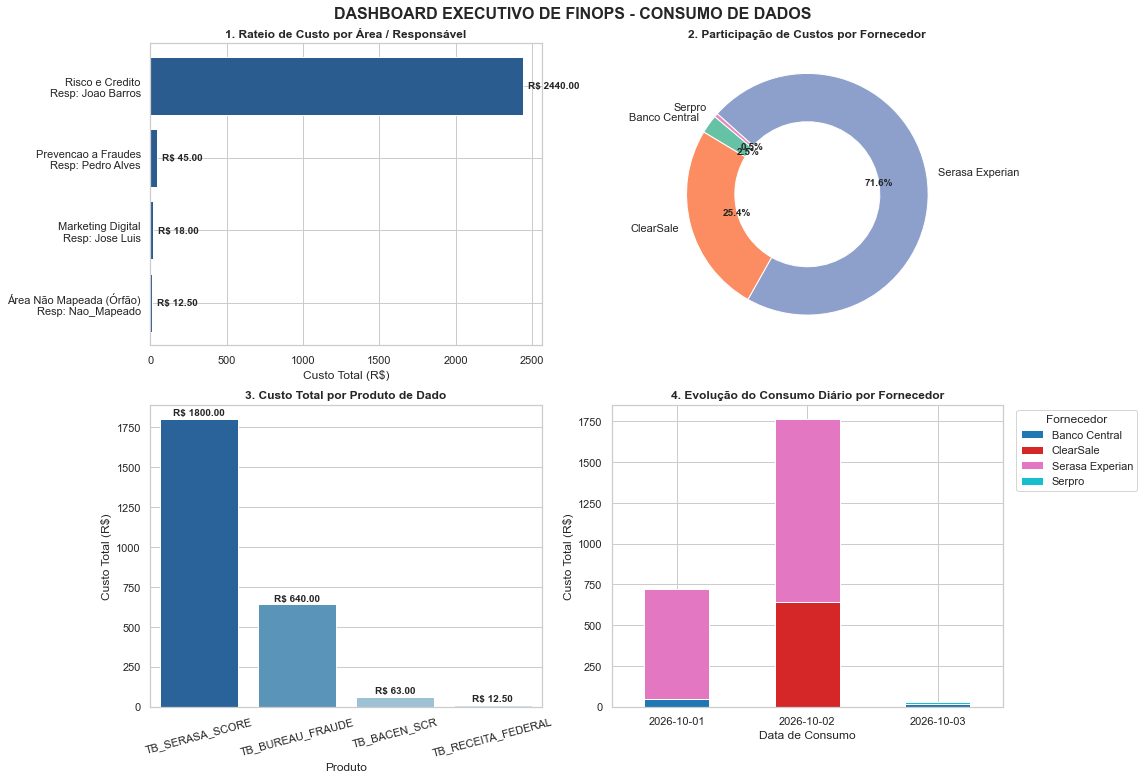

In [ ]:
# =============================================================================
# DASHBOARD
# =============================================================================

# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'

# Garantindo a coluna de responsável condicional
df_final['responsavel_exibicao'] = df_final.apply(
    lambda row: row['nome_lider'] if row['possui_lider_negocio'] == 'Sim' else row['respo_area'], 
    axis=1
)

# Criando figura com grade 2x2 para o Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('DASHBOARD EXECUTIVO DE FINOPS - CONSUMO DE DADOS', fontsize=16, fontweight='bold', y=0.98)

# -------------------------------------------------------------------------
# 1. CUSTO TOTAL POR ÁREA E RESPONSÁVEL
# -------------------------------------------------------------------------
custo_area = df_final.groupby(['nome_area', 'responsavel_exibicao'])['custo_total'].sum().reset_index()
custo_area['area_label'] = custo_area['nome_area'] + '\nResp: ' + custo_area['responsavel_exibicao']
custo_area = custo_area.sort_values(by='custo_total', ascending=True)

ax1 = axes[0, 0]
bars1 = ax1.barh(custo_area['area_label'], custo_area['custo_total'], color='#2b5c8f')
ax1.set_title('1. Rateio de Custo por Área / Responsável', fontweight='bold', fontsize=12)
ax1.set_xlabel('Custo Total (R$)')
ax1.bar_label(bars1, fmt='R$ %.2f', padding=5, fontweight='bold')

# -------------------------------------------------------------------------
# 2. PARTICIPAÇÃO POR FORNECEDOR 
# -------------------------------------------------------------------------
custo_fornecedor = df_final.groupby('fornecedor')['custo_total'].sum().reset_index()

ax2 = axes[0, 1]
wedges, texts, autotexts = ax2.pie(
    custo_fornecedor['custo_total'], 
    labels=custo_fornecedor['fornecedor'], 
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2', len(custo_fornecedor)),
    wedgeprops=dict(width=0.4, edgecolor='w')
)
plt.setp(autotexts, size=10, weight="bold")
ax2.set_title('2. Participação de Custos por Fornecedor', fontweight='bold', fontsize=12)

# -------------------------------------------------------------------------
# 3. RANKING DE CUSTO POR PRODUTO DE DADO
# -------------------------------------------------------------------------
custo_produto = df_final.groupby('produto_dado')['custo_total'].sum().reset_index().sort_values(by='custo_total', ascending=False)

ax3 = axes[1, 0]
bars3 = sns.barplot(data=custo_produto, x='produto_dado', y='custo_total', ax=ax3, palette='Blues_r')
ax3.set_title('3. Custo Total por Produto de Dado', fontweight='bold', fontsize=12)
ax3.set_xlabel('Produto')
ax3.set_ylabel('Custo Total (R$)')
ax3.tick_params(axis='x', rotation=15)

for p in bars3.patches:
    bars3.annotate(f'R$ {p.get_height():.2f}', 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

# -------------------------------------------------------------------------
# 4. EVOLUÇÃO DIÁRIA DO CUSTO POR FORNECEDOR
# -------------------------------------------------------------------------
custo_tempo = df_final.groupby(['data_consumo', 'fornecedor'])['custo_total'].sum().unstack().fillna(0)

ax4 = axes[1, 1]
custo_tempo.plot(kind='bar', stacked=True, ax=ax4, colormap='tab10', width=0.5)
ax4.set_title('4. Evolução do Consumo Diário por Fornecedor', fontweight='bold', fontsize=12)
ax4.set_xlabel('Data de Consumo')
ax4.set_ylabel('Custo Total (R$)')
ax4.tick_params(axis='x', rotation=0)
ax4.legend(title='Fornecedor', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [22]:
# =============================================================================
# Exportação de Dados
# =============================================================================
# Aqui podemos configurar o que queremos exportar e quais formatos desejamos

# Definindo o caminho de destino na pasta 'arquivos'
caminho_csv = os.path.join(pasta_arquivos, 'base_tratada_finops.csv')

# Exportando o DataFrame consolidado para CSV
df_final.to_csv(caminho_csv, index=False, encoding='utf-8-sig')

print(f"Base tratada exportada com sucesso para: {caminho_csv}")

# Salvando a figura do dashboard diretamente em arquivo PDF
caminho_pdf = os.path.join(pasta_arquivos, 'dashboard_executivo_finops.pdf')
fig.savefig(caminho_pdf, format='pdf', bbox_inches='tight', dpi=300)

plt.show()

print(f"Dashboard em PDF exportado com sucesso para: {caminho_pdf}")

Base tratada exportada com sucesso para: .\arquivos\base_tratada_finops.csv
Dashboard em PDF exportado com sucesso para: .\arquivos\dashboard_executivo_finops.pdf
